# LLMs Evaluation

Everything below comes from the committed ledger,
`backend/evaluation/results/runs.jsonl`. Nine models ran the same corpus twice, once
with six worked examples in the prompt and once with none. No model is called here
and no verdict is recomputed; this notebook only arranges what was measured. Every
count is read from the file, so the prose follows the ledger when the ledger changes.

The counting comes from `evaluation.report`, the same functions behind
`python -m evaluation.report`. The notebook and the command-line report cannot
disagree.

Run the cells in order. Nothing outside the repository is needed.

## 1. The evidence

In [1]:
%matplotlib inline

import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D

#: Also write each figure beside the ledger, as a PNG ready for a document.
EXPORT_FIGURES = False


def find_backend(start: Path) -> Path:
    """The directory holding ``evaluation/results/runs.jsonl``, from ``start`` up."""
    for candidate in [start, *start.parents]:
        for root in (candidate / "backend", candidate):
            if (root / "evaluation" / "results" / "runs.jsonl").is_file():
                return root
    raise FileNotFoundError(f"no evaluation/results/runs.jsonl above {start}")


BACKEND = find_backend(Path.cwd())
LEDGER = BACKEND / "evaluation" / "results" / "runs.jsonl"
FIGDIR = LEDGER.parent / "figures"
sys.path.insert(0, str(BACKEND))

from evaluation import corpus, report, scoring

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.titlesize": 12}
)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 200)
# A field tally key reads ``notional_1: 80000000.0 != 8000000.0``, so leave the
# column width alone rather than let a table elide the evidence it is quoting.
pd.set_option("display.max_colwidth", None)


#: The kinds of parser on the record, grouped into the three families a chart
#: separates: the hand-written rule set, models running on this machine, and models
#: reached over the network.
FAMILY_OF_KIND = {"baseline": "baseline", "ollama": "local", "openrouter": "hosted"}


def short_label(model_id: str) -> str:
    """The model id as a chart names it."""
    if model_id == "rule-based":
        return "rules"
    return model_id.split("/")[-1].replace(":", "-")


#: One colour per family, so local and hosted are never confused in a figure.
FAMILY_COLOUR = {"baseline": "#555555", "local": "#2b6cb0", "hosted": "#c05621"}


def save(fig, name: str) -> None:
    """Write a figure out, when exporting is on."""
    if EXPORT_FIGURES:
        FIGDIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGDIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
records = [
    json.loads(line)
    for line in LEDGER.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
headers = pd.DataFrame(record for record in records if record["kind"] == "run")
items = pd.DataFrame(record for record in records if record["kind"] == "item")

headers["family"] = headers["model_kind"].map(FAMILY_OF_KIND)
assert headers["family"].notna().all(), sorted(set(headers["model_kind"]) - set(FAMILY_OF_KIND))

#: The number of worked examples a run was shown. ``shots`` went into the header after
#: the first ten runs were written, so its absence there is read as the whole set, not as
#: zero, which would merge a run that had examples with one that had none. The column
#: arrives as a float because pandas fills the ten headers that lack the key with NaN.
def condition_of(value) -> str:
    if pd.isna(value):
        return "6-shot"
    return f"{int(value)}-shot"

if "shots" not in headers:
    headers["shots"] = None
headers["condition"] = headers["shots"].map(condition_of)
assert set(headers["condition"]) == {"6-shot", "0-shot"}, sorted(set(headers["condition"]))

headers["label"] = headers["model_id"].map(short_label)
# Two conditions of one model share a model id, so the condition disambiguates them.
# A chart indexed by label would otherwise merge the pair without saying so.
headers["label"] = headers.apply(
    lambda row: f"{row['label']} · {row['condition']}", axis=1
)
assert headers["label"].is_unique, "two runs share a label; a figure would merge them"
headers["_order"] = pd.Categorical(
    headers["family"], ["baseline", "local", "hosted"], ordered=True
)
headers = headers.sort_values(["_order", "started_at"]).reset_index(drop=True)

RUN_IDS = list(headers["run_id"])
LABEL = dict(zip(headers["run_id"], headers["label"]))
FAMILY = dict(zip(headers["run_id"], headers["family"]))
by_run = {
    rid: [r for r in records if r["kind"] == "item" and r["run_id"] == rid]
    for rid in RUN_IDS
}

print(f"ledger  {LEDGER.relative_to(BACKEND.parent)}")
print(f"sha256  {hashlib.sha256(LEDGER.read_bytes()).hexdigest()[:16]}")
print(f"shape   {len(records)} records = {len(headers)} runs x {len(items) // len(headers)} items")
print(f"corpus  {headers['corpus_sha256'].iloc[0][:16]}  trade date {headers['trade_date'].iloc[0]}")
print(f"commit  {sorted(set(headers['git_sha'].str[:7]))}  dirty {sorted(set(headers['git_dirty']))}")
print(f"prompt  {sorted({str(v)[:12] for v in headers['system_prompt_sha256']})}")
print(f"shots   {sorted(headers['condition'].unique())}")

ledger  backend\evaluation\results\runs.jsonl
sha256  1f9af98067430204
shape   7163 records = 19 runs x 376 items
corpus  fc14ec84d90c9c01  trade date 2026-09-11
commit  ['9381d7b', 'baa5ca4']  dirty [False]
prompt  ['523663a135c4']
shots   ['0-shot', '6-shot']


Every run covers the whole corpus and records the commit it started from. All
nineteen headers agree on the corpus digest, the prompt digest and the runner and
scorer versions. That agreement is what makes the numbers comparable;
`report.compare_headers` enforces it, and section 10 runs the check again.

The demonstration count is recorded but not enforced. The examples are the treatment,
so differencing the two conditions is the measurement, not a mistake.

In [3]:
provenance = headers[
    [
        "label",
        "run_id",
        "model_id",
        "model_kind",
        "provider_model",
        "condition",
        "splits",
        "item_count",
        "item_limit",
        "git_sha",
        "git_dirty",
        "started_at",
    ]
].copy()
provenance["splits"] = provenance["splits"].map("".join)
provenance["git_sha"] = provenance["git_sha"].str[:7]
provenance["started_at"] = provenance["started_at"].str.replace("+00:00", "", regex=False)
provenance = provenance.fillna("—")
display(provenance.reset_index(drop=True))

,label,run_id,model_id,model_kind,provider_model,condition,splits,item_count,item_limit,git_sha,git_dirty,started_at
0,rules · 6-shot,baseline,rule-based,baseline,—,6-shot,ABCD,376,—,baa5ca4,False,2026-09-24T23:39:51
1,llama3.2-3b · 6-shot,ollama-llama32-3b,llama3.2:3b,ollama,llama3.2:3b,6-shot,ABCD,376,—,baa5ca4,False,2026-09-24T23:39:52
2,qwen2.5-3b · 6-shot,ollama-qwen25-3b,qwen2.5:3b,ollama,qwen2.5:3b,6-shot,ABCD,376,—,baa5ca4,False,2026-09-25T00:43:52
3,gemma2-2b · 6-shot,ollama-gemma2-2b,gemma2:2b,ollama,gemma2:2b,6-shot,ABCD,376,—,baa5ca4,False,2026-09-25T02:10:36
4,phi3.5 · 6-shot,ollama-phi35,phi3.5,ollama,phi3.5,6-shot,ABCD,376,—,baa5ca4,False,2026-09-25T04:52:29
5,llama3.2-3b · 0-shot,ollama-llama32-3b-0shot,llama3.2:3b,ollama,llama3.2:3b,0-shot,ABCD,376,—,9381d7b,False,2026-09-26T11:38:56
6,qwen2.5-3b · 0-shot,ollama-qwen25-3b-0shot,qwen2.5:3b,ollama,qwen2.5:3b,0-shot,ABCD,376,—,9381d7b,False,2026-09-26T12:02:23
7,gemma2-2b · 0-shot,ollama-gemma2-2b-0shot,gemma2:2b,ollama,gemma2:2b,0-shot,ABCD,376,—,9381d7b,False,2026-09-26T14:10:27
8,phi3.5 · 0-shot,ollama-phi35-0shot,phi3.5,ollama,phi3.5,0-shot,ABCD,376,—,9381d7b,False,2026-09-26T16:46:54
9,gpt-5.6-luna · 6-shot,openrouter-gpt56-luna,openai/gpt-5.6-luna,openrouter,openai/gpt-5.6-luna,6-shot,ABCD,376,—,baa5ca4,False,2026-09-25T08:36:32


### What one item record holds

Each item record holds the verdict (`outcome`, `correct`, `wrong`), how it was
reached (`detail`, `error_type`), what the call cost (`latency_ms`, tokens, `usd`),
and the model's own JSON under `raw`.

`wrong` and `defaulted_fields` are lists. `usd` is `None` for every local run, since
a local model reports no usage. A missing cost stays missing; filling it with zero
would let it count in an average.

In [4]:
field_kinds = {
    "capability": "the tag the item tests",
    "instrument_type": "SPOT / FORWARD / OPTION, or None on the refusal arm",
    "outcome": "parsed / refused / crashed / timeout",
    "correct": "the verdict; on D this means correctly refused",
    "wrong": "stated fields the golden disagreed with",
    "detail": "the verdict in words",
    "error_type": "the exception, when there was one",
    "error": "the exception message or the refusal reason",
    "defaulted_fields": "fields the resolver invented",
    "default_count": "how many of them",
    "latency_ms": "one item, start to verdict",
    "prompt_tokens / completion_tokens / total_tokens": "as the provider reported them",
    "usd": "cost, when the provider states it",
    "served_model": "who actually answered, which a gateway may redirect",
    "raw": "the model's own JSON, unmodified",
    "pair_id": "links a B item to its C twin",
    "reason": "on D, the refusal that was required",
}
pd.DataFrame(
    {"field": list(field_kinds), "meaning": list(field_kinds.values())}
).set_index("field")

,meaning
field,
capability,the tag the item tests
instrument_type,"SPOT / FORWARD / OPTION, or None on the refusal arm"
outcome,parsed / refused / crashed / timeout
correct,the verdict; on D this means correctly refused
wrong,stated fields the golden disagreed with
detail,the verdict in words
error_type,"the exception, when there was one"
error,the exception message or the refusal reason
defaulted_fields,fields the resolver invented


## 2. The two arms

The corpus asks two questions, and they are counted separately.

Parse arm (A, B, C): a valid ticket exists. `correct` means every field the text
states was matched. A field the golden leaves null was never stated, so a parser is
free to invent it and is not scored on it.

Refusal arm (D): no valid ticket exists. The only correct answer is a refusal, so
`correct` here means the model refused. Answering with a trade is wrong.

A and B are the same questions in familiar wording, C the same tickets in shifted
wording. Section 5 covers that.

In [5]:
PARSE_ARM = ("A", "B", "C")
REFUSAL_ARM = "D"


def tally(rows) -> tuple[int, int]:
    """Right and total — the two numbers every rate is taken over."""
    rows = list(rows)
    return sum(1 for r in rows if r["correct"]), len(rows)


def latency_stats(rows) -> dict:
    # Percentiles and the mean of the per-item latency, in ms.
    ordered = sorted(r["latency_ms"] for r in rows)
    return {
        "latency_p25": report.percentile(ordered, 25),
        "latency_p50": report.percentile(ordered, 50),
        "latency_p75": report.percentile(ordered, 75),
        "latency_mean": sum(ordered) / len(ordered),
    }


def usd_mean(rows) -> float | None:
    # Mean over the items that carried a price; None when none did, because a local
    # run reports no cost and an average over nothing would read as free.
    priced = [r["usd"] for r in rows if r["usd"] is not None]
    return sum(priced) / len(priced) if priced else None


summary = pd.DataFrame(
    [
        {
            "run_id": rid,
            "label": LABEL[rid],
            "family": FAMILY[rid],
            "items": len(by_run[rid]),
            "parse_correct": tally(r for r in by_run[rid] if r["split"] in PARSE_ARM)[0],
            "parse_n": tally(r for r in by_run[rid] if r["split"] in PARSE_ARM)[1],
            "refuse_correct": tally(r for r in by_run[rid] if r["split"] == REFUSAL_ARM)[0],
            "refuse_n": tally(r for r in by_run[rid] if r["split"] == REFUSAL_ARM)[1],
            "overall_correct": tally(by_run[rid])[0],
            "overall_n": tally(by_run[rid])[1],
            # What the parser did with each item, as opposed to whether it was right.
            # Each count is over the pool its column names.
            "d_refused": sum(
                1
                for r in by_run[rid]
                if r["split"] == REFUSAL_ARM and r["outcome"] == scoring.REFUSED
            ),
            "abc_parsed": sum(
                1
                for r in by_run[rid]
                if r["split"] in PARSE_ARM and r["outcome"] == scoring.PARSED
            ),
            "abc_refused": sum(
                1
                for r in by_run[rid]
                if r["split"] in PARSE_ARM and r["outcome"] == scoring.REFUSED
            ),
            "crashed": sum(1 for r in by_run[rid] if r["outcome"] == scoring.CRASHED),
            "timed_out": sum(1 for r in by_run[rid] if r["outcome"] == scoring.TIMEOUT),
            "usd_mean": usd_mean(by_run[rid]),
            **latency_stats(by_run[rid]),
        }
        for rid in RUN_IDS
    ]
).assign(
    parse=lambda d: d.parse_correct / d.parse_n,
    refuse=lambda d: d.refuse_correct / d.refuse_n,
    overall=lambda d: d.overall_correct / d.overall_n,
)

arms = summary


def shown(rate, correct, total) -> str:
    """A rate as it is printed, beside the count it was taken over."""
    return f"{report.percent(rate)} ({correct}/{total})"


arms_view = pd.DataFrame(
    {
        "refused D /40": [
            shown(record["d_refused"] / record["refuse_n"], record["d_refused"], record["refuse_n"])
            for record in summary.to_dict("records")
        ],
        "parsed ABC /336": [
            shown(record["abc_parsed"] / record["parse_n"], record["abc_parsed"], record["parse_n"])
            for record in summary.to_dict("records")
        ],
        "correct ABC /336": [
            shown(record["parse"], record["parse_correct"], record["parse_n"])
            for record in summary.to_dict("records")
        ],
        "refused ABC /336": [
            shown(record["abc_refused"] / record["parse_n"], record["abc_refused"], record["parse_n"])
            for record in summary.to_dict("records")
        ],
        "correct overall /376": [
            shown(record["overall"], record["overall_correct"], record["overall_n"])
            for record in summary.to_dict("records")
        ],
        "crash /376": [
            shown(record["crashed"] / record["overall_n"], record["crashed"], record["overall_n"])
            for record in summary.to_dict("records")
        ],
        "timeout /376": [
            shown(record["timed_out"] / record["overall_n"], record["timed_out"], record["overall_n"])
            for record in summary.to_dict("records")
        ],
        "p25 latency": [f"{record['latency_p25']:,.0f}ms" for record in summary.to_dict("records")],
        "p50 latency": [f"{record['latency_p50']:,.0f}ms" for record in summary.to_dict("records")],
        "p75 latency": [f"{record['latency_p75']:,.0f}ms" for record in summary.to_dict("records")],
        "mean latency": [f"{record['latency_mean']:,.0f}ms" for record in summary.to_dict("records")],
        "mean usd": [
            # pandas turns the None from usd_mean() into NaN, so test for either.
            "—" if pd.isna(record["usd_mean"]) else f"${record['usd_mean']:.4f}"
            for record in summary.to_dict("records")
        ],
    },
    index=summary["label"].rename("run"),
)
display(arms_view)
print(
    "refused D is out of the D sentences; parsed, correct and refused ABC are out of A+B+C; "
    "correct overall and the two faults are out of every item. Latency is per item, and mean "
    "usd is over the items that carried a price"
)

,refused D /40,parsed ABC /336,correct ABC /336,refused ABC /336,correct overall /376,crash /376,timeout /376,p25 latency,p50 latency,p75 latency,mean latency,mean usd
run,,,,,,,,,,,,
rules · 6-shot,100.0% (40/40),75.0% (252/336),66.7% (224/336),25.0% (84/336),70.2% (264/376),0.0% (0/376),0.0% (0/376),0ms,0ms,0ms,0ms,—
llama3.2-3b · 6-shot,87.5% (35/40),42.9% (144/336),20.8% (70/336),57.1% (192/336),27.9% (105/376),0.0% (0/376),0.0% (0/376),"3,473ms","4,648ms","17,626ms","10,211ms",—
qwen2.5-3b · 6-shot,82.5% (33/40),61.3% (206/336),41.1% (138/336),38.7% (130/336),45.5% (171/376),0.0% (0/376),0.0% (0/376),"3,489ms","16,341ms","21,110ms","13,839ms",—
gemma2-2b · 6-shot,67.5% (27/40),96.1% (323/336),61.9% (208/336),3.9% (13/336),62.5% (235/376),0.0% (0/376),0.0% (0/376),"23,887ms","24,248ms","26,129ms","25,830ms",—
phi3.5 · 6-shot,82.5% (33/40),90.2% (303/336),69.6% (234/336),9.5% (32/336),71.0% (267/376),0.0% (0/376),0.3% (1/376),"32,621ms","33,747ms","40,128ms","35,749ms",—
llama3.2-3b · 0-shot,100.0% (40/40),0.9% (3/336),0.6% (2/336),98.2% (330/336),11.2% (42/376),0.0% (0/376),0.8% (3/376),"1,704ms","2,017ms","2,901ms","3,741ms",—
qwen2.5-3b · 0-shot,62.5% (25/40),88.4% (297/336),28.9% (97/336),11.6% (39/336),32.4% (122/376),0.0% (0/376),0.0% (0/376),"17,943ms","19,713ms","20,742ms","20,433ms",—
gemma2-2b · 0-shot,55.0% (22/40),90.5% (304/336),62.2% (209/336),9.5% (32/336),61.4% (231/376),0.0% (0/376),0.0% (0/376),"22,713ms","24,362ms","27,028ms","24,963ms",—
phi3.5 · 0-shot,40.0% (16/40),93.2% (313/336),28.0% (94/336),6.8% (23/336),29.3% (110/376),0.0% (0/376),0.0% (0/376),"34,438ms","37,809ms","42,887ms","41,580ms",—


refused D is out of the D sentences; parsed, correct and refused ABC are out of A+B+C; correct overall and the two faults are out of every item. Latency is per item, and mean usd is over the items that carried a price


## 3. The two arms together

The two arms do not trade off. A model that parses well also refuses well, and the
ranking on one axis broadly tracks the ranking on the other. The corner that would
mean parsing everything while refusing nothing is empty. Both conditions are plotted,
lightened for zero-shot and joined by a dashed line, so each model appears twice and
the distance between its pair is what the worked examples bought. Each name is set
against that model's six-shot run.

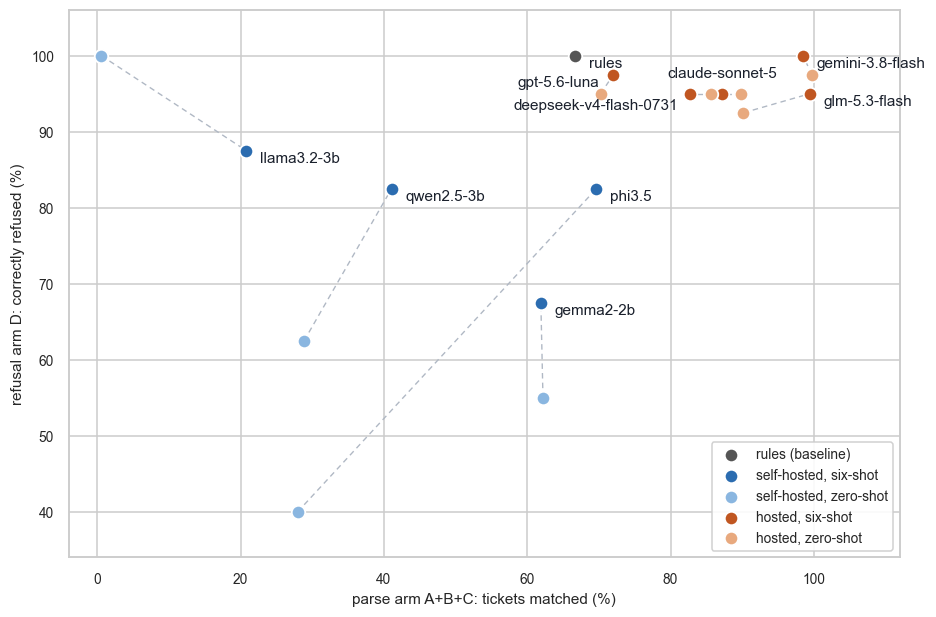

In [20]:
# One colour per family, lightened for the zero-shot condition, so a model's two runs
# are recognisable as a pair without a second legend or a second chart.
CONDITION_COLOUR = {
    ("baseline", "6-shot"): "#555555",
    ("local", "6-shot"): "#2b6cb0",
    ("local", "0-shot"): "#8ab6e0",
    ("hosted", "6-shot"): "#c05621",
    ("hosted", "0-shot"): "#e8a97e",
}
CONDITION_TEXT = {
    ("baseline", "6-shot"): "rules (baseline)",
    ("local", "6-shot"): "self-hosted, six-shot",
    ("local", "0-shot"): "self-hosted, zero-shot",
    ("hosted", "6-shot"): "hosted, six-shot",
    ("hosted", "0-shot"): "hosted, zero-shot",
}
LEGEND_ORDER = [
    ("baseline", "6-shot"),
    ("local", "6-shot"),
    ("local", "0-shot"),
    ("hosted", "6-shot"),
    ("hosted", "0-shot"),
]
# The zero-shot labels are set in grey against the darker six-shot ones, so the pair
# reads as one model written twice rather than as two models sharing a name.
CONDITION_TEXT_COLOUR = {"6-shot": "#1a202c", "0-shot": "#6b7280"}

arms_by_run = summary.set_index("run_id")[["parse", "refuse"]]
scatter = (
    headers[["run_id", "model_id", "family", "condition"]]
    .join(arms_by_run, on="run_id")
    .assign(
        name=lambda frame: frame["model_id"].map(short_label),
        x=lambda frame: 100 * frame["parse"],
        y=lambda frame: 100 * frame["refuse"],
    )
)

points = [
    (
        row.x,
        row.y,
        row.name,
        CONDITION_COLOUR[(row.family, row.condition)],
        CONDITION_TEXT_COLOUR[row.condition],
        row.condition,
    )
    for row in scatter.itertuples()
]

markers_xy = [(x, y) for x, y, _, _, _, _ in points]
# The six-shot run of each model carries the name; its zero-shot twin is the lighter
# point at the other end of the dashed line.
labelled = [
    (x, y, text, text_colour)
    for x, y, text, _, text_colour, condition in points
    if condition == "6-shot"
]


def repel(ax, markers_xy, labelled, fontsize=10, blocked=()):
    # Label each model at the first free slot, most crowded model first. A single fixed
    # offset cannot fit the cluster at the top right, and placing the sparse points first
    # crowds the dense ones out of every nearby slot. Candidates are a ring of sixteen
    # directions at twelve distances, tried nearest first; a label pushed beyond a couple
    # of character widths gets a leader line back to its point. Every run is a marker to
    # avoid, but only the six-shot run of each model carries the name, since the pair sits
    # within a couple of points of each other and two labels there would overlap anyway.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    # Anything already drawn that a label must not cover, such as the legend.
    blocked_boxes = [
        item.get_window_extent(renderer).expanded(1.02, 1.06) for item in blocked
    ]
    ring = [
        (int(round(radius * np.cos(angle))), int(round(radius * np.sin(angle))))
        for radius in (9, 14, 20, 27, 35, 44, 54, 65, 78, 92, 108, 126)
        for angle in np.radians(np.arange(0.0, 360.0, 22.5))
    ]
    markers = [ax.transData.transform((x, y)) for x, y in markers_xy]

    def crowding(x, y) -> int:
        # How many runs sit within a label's width, in pixels.
        px, py = ax.transData.transform((x, y))
        return sum(1 for qx, qy in markers if np.hypot(px - qx, py - qy) < 95)

    placed = []
    done = set()
    for index in sorted(
        range(len(labelled)), key=lambda i: -crowding(labelled[i][0], labelled[i][1])
    ):
        x, y, text, text_colour = labelled[index]
        for dx, dy in ring:
            far = np.hypot(dx, dy) > 14
            label = ax.annotate(
                text,
                (x, y),
                textcoords="offset points",
                xytext=(dx, dy),
                fontsize=fontsize,
                color=text_colour,
                ha="left" if dx > 0 else "right" if dx < 0 else "center",
                va="bottom" if dy > 0 else "top",
                zorder=4,
                arrowprops=(
                    {
                        "arrowstyle": "-",
                        "linewidth": 0.7,
                        "color": "#a0aec0",
                        "shrinkA": 5,
                        "shrinkB": 1,
                    }
                    if far
                    else None
                ),
            )
            box = label.get_window_extent(renderer).expanded(1.08, 1.30)
            if any(box.overlaps(other) for other in placed + blocked_boxes) or any(
                box.contains(*marker) for marker in markers
            ):
                label.remove()
                continue
            placed.append(box)
            done.add(index)
            break
    unplaced = [labelled[i][2] for i in range(len(labelled)) if i not in done]
    assert not unplaced, f"no free slot for {unplaced}"


fig, ax = plt.subplots(figsize=(8.4, 5.5))
# A dashed line per model joins its two conditions, so the pair reads as one model
# moving between them rather than as two runs that happen to share a name.
for _model, group in scatter.groupby("model_id"):
    if len(group) == 2:
        pair = group.sort_values("condition")
        ax.plot(
            pair["x"],
            pair["y"],
            color="#b0b8c4",
            linewidth=0.9,
            linestyle=(0, (4, 3)),
            zorder=2,
        )
handles: dict[tuple[str, str], object] = {}
for row in scatter.itertuples():
    point = ax.scatter(
        row.x,
        row.y,
        s=78,
        color=CONDITION_COLOUR[(row.family, row.condition)],
        edgecolor="white",
        linewidth=1.2,
        zorder=3,
    )
    handles.setdefault((row.family, row.condition), point)
ax.set_xlabel("parse arm A+B+C: tickets matched (%)", fontsize=10)
ax.set_ylabel("refusal arm D: correctly refused (%)", fontsize=10)
ax.set_xlim(-4, 112)
ax.set_ylim(34, 106)
ax.set_xticks(range(0, 101, 20))
ax.set_yticks(range(40, 101, 10))
ax.tick_params(labelsize=9)
# The legend goes down first so the label placer treats it as occupied space, and the
# limits go down first because repel() reads pixel positions.
legend = ax.legend(
    [handles[key] for key in LEGEND_ORDER],
    [CONDITION_TEXT[key] for key in LEGEND_ORDER],
    loc="lower right",
    frameon=True,
    framealpha=0.9,
    fontsize=9,
)
repel(ax, markers_xy, labelled, blocked=[legend])
save(fig, "arm-frontier")

Every hosted run beats every local run on the parse axis, and the two groups stay
apart across it. The refusal axis is not as clean, because a model that declines
almost everything scores at the top of it: `llama3.2-3b` reaches every refusal when it
is given no examples, while parsing practically nothing.

The lower left of the plot is where the new failure lives. A model can lose an item by
declining a ticket that was bookable, and that costs it exactly what inventing one
costs. Section 7 covers both directions.

## 4. What the worked examples are worth

Nine models ran the corpus twice, once with six worked examples in the prompt and
once with none. Nothing else differs between the pair, so the difference is the
effect of the examples.

The baseline has no second run. It reads only the last user turn, so the examples
never reach it.

The count is recorded in the header but not enforced, so the two conditions can be
differenced. That is what the second run is for.

In [7]:
arm = summary.merge(headers[["run_id", "model_id", "label", "condition"]], on="run_id")
six = arm[arm["condition"] == "6-shot"].set_index("model_id")
zero = arm[arm["condition"] == "0-shot"].set_index("model_id")
# The rule-based baseline reads only the last user turn, so it has no zero-shot run:
# the intersection is the paired models, and it is nine rather than ten.
ABLATED = [m for m in six.index if m in zero.index]

ablation = pd.DataFrame(
    {
        "parse 6-shot": six.loc[ABLATED, "parse"].to_numpy() * 100,
        "parse 0-shot": zero.loc[ABLATED, "parse"].to_numpy() * 100,
        "D 6-shot": six.loc[ABLATED, "refuse"].to_numpy() * 100,
        "D 0-shot": zero.loc[ABLATED, "refuse"].to_numpy() * 100,
        # Over-declining is counted apart from accuracy: it is the failure the zero-shot
        # condition amplifies, and a rate alone would hide it behind the D column.
        "wrongly refused 6-shot": [
            sum(
                1
                for r in by_run[six.loc[m, "run_id"]]
                if r["split"] in PARSE_ARM and r["outcome"] == scoring.REFUSED
            )
            for m in ABLATED
        ],
        "wrongly refused 0-shot": [
            sum(
                1
                for r in by_run[zero.loc[m, "run_id"]]
                if r["split"] in PARSE_ARM and r["outcome"] == scoring.REFUSED
            )
            for m in ABLATED
        ],
    },
    index=[short_label(m) for m in ABLATED],
)
ablation["parse cost"] = ablation["parse 0-shot"] - ablation["parse 6-shot"]
ablation["D cost"] = ablation["D 0-shot"] - ablation["D 6-shot"]
display(ablation.round(1))
print(f"mean parse cost {ablation['parse cost'].mean():+.1f}pp, mean D cost {ablation['D cost'].mean():+.1f}pp")

,parse 6-shot,parse 0-shot,D 6-shot,D 0-shot,wrongly refused 6-shot,wrongly refused 0-shot,parse cost,D cost
llama3.2-3b,20.8,0.6,87.5,100.0,192,330,-20.2,12.5
qwen2.5-3b,41.1,28.9,82.5,62.5,130,39,-12.2,-20.0
gemma2-2b,61.9,62.2,67.5,55.0,13,32,0.3,-12.5
phi3.5,69.6,28.0,82.5,40.0,32,23,-41.7,-42.5
gpt-5.6-luna,72.0,70.2,97.5,95.0,94,100,-1.8,-2.5
glm-5.3-flash,99.4,90.2,95.0,92.5,1,27,-9.2,-2.5
deepseek-v4-flash-0731,82.7,89.9,95.0,95.0,55,22,7.1,0.0
gemini-3.8-flash,98.5,99.7,100.0,97.5,0,0,1.2,-2.5
claude-sonnet-5,87.2,85.7,95.0,95.0,41,45,-1.5,0.0


mean parse cost -8.7pp, mean D cost -7.8pp


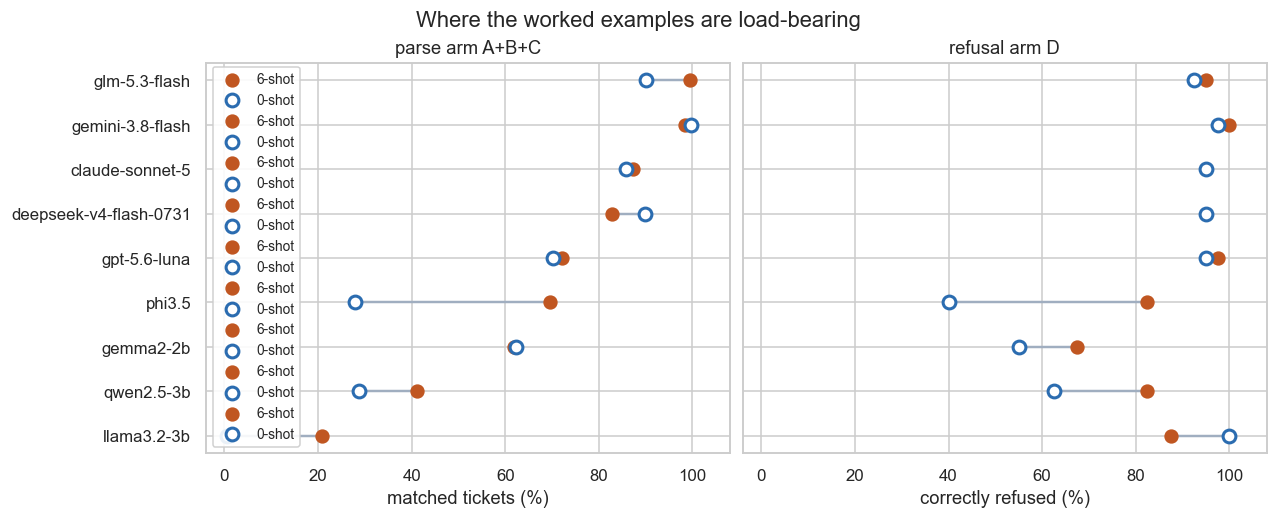

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)
order = ablation.sort_values("parse 6-shot").index
for ax, (kind, base, bare, title) in zip(
    axes,
    (
        ("parse arm A+B+C", "parse 6-shot", "parse 0-shot", "matched tickets (%)"),
        ("refusal arm D", "D 6-shot", "D 0-shot", "correctly refused (%)"),
    ),
):
    for position, model in enumerate(order):
        left, right = ablation.loc[model, base], ablation.loc[model, bare]
        ax.plot([left, right], [position, position], color="#a0aec0", linewidth=1.6, zorder=2)
        ax.scatter([left], [position], s=70, color="#c05621", zorder=3, label="6-shot")
        ax.scatter([right], [position], s=70, facecolor="white", edgecolor="#2b6cb0", linewidth=2, zorder=3, label="0-shot")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order)
    ax.set_title(kind)
    ax.set_xlabel(title)
    ax.set_xlim(-4, 108)
    if ax is axes[0]:
        ax.legend(loc="lower left", frameon=True, framealpha=0.9, fontsize=9)
fig.suptitle("Where the worked examples are load-bearing")
save(fig, "ablation")

The examples carry the small models and barely matter to the large ones. The four
smallest lose the most; two of the best lose nothing on the refusal arm, and one
gains on parsing without them.

A perfect refusal arm does not mean a model reads well. The weakest model reaches
100% on D because its parsing collapsed: it declines nearly every valid ticket, so
refusing everything buys the whole arm. Read D next to the over-declining count,
never on its own.

## 5. Per split

A, B and C step through the same cell table, so all three ask the same questions in
the same order. B and C are one ticket in two spellings; `B[i]` and `C[i]` share a
`pair_id`.

D is a fixed list of sentences that are not tickets.

In [9]:
split_view = pd.DataFrame(
    [
        {
            "label": LABEL[rid],
            **{
                split: "{} ({}/{})".format(
                    report.percent(per_split.get("accuracy")),
                    per_split.get("correct"),
                    per_split.get("n"),
                )
                for split, per_split in report.split_summary(
                    by_run[rid], expected=corpus.SPLIT_SIZES
                ).items()
            },
        }
        for rid in RUN_IDS
    ]
)
display(split_view)
print("corpus:", corpus.SPLIT_SIZES)

,label,A,B,C,D
0,rules · 6-shot,100.0% (112/112),100.0% (112/112),0.0% (0/112),100.0% (40/40)
1,llama3.2-3b · 6-shot,28.6% (32/112),19.6% (22/112),14.3% (16/112),87.5% (35/40)
2,qwen2.5-3b · 6-shot,47.3% (53/112),40.2% (45/112),35.7% (40/112),82.5% (33/40)
3,gemma2-2b · 6-shot,65.2% (73/112),65.2% (73/112),55.4% (62/112),67.5% (27/40)
4,phi3.5 · 6-shot,76.8% (86/112),74.1% (83/112),58.0% (65/112),82.5% (33/40)
5,llama3.2-3b · 0-shot,1.8% (2/112),0.0% (0/112),0.0% (0/112),100.0% (40/40)
6,qwen2.5-3b · 0-shot,31.2% (35/112),33.0% (37/112),22.3% (25/112),62.5% (25/40)
7,gemma2-2b · 0-shot,64.3% (72/112),67.0% (75/112),55.4% (62/112),55.0% (22/40)
8,phi3.5 · 0-shot,33.0% (37/112),29.5% (33/112),21.4% (24/112),40.0% (16/40)
9,gpt-5.6-luna · 6-shot,73.2% (82/112),71.4% (80/112),71.4% (80/112),97.5% (39/40)


corpus: {'A': 112, 'B': 112, 'C': 112, 'D': 40}


The familiar and shifted arms sit close together for every model, which is what the
corpus is built for: changing the wording should not change the trade. The size of
the gap matters, not its sign.

In [10]:
shift_rows = []
for rid in RUN_IDS:
    per_capability = sorted(
        report.contrast(by_run[rid]),
        key=lambda row: row["drop"] if row["drop"] is not None else 0.0,
    )
    shifted = [row for row in per_capability if row["drop"] is not None]
    shift_rows.append(
        {
            "label": LABEL[rid],
            "capabilities made worse by shifting": sum(1 for row in shifted if row["drop"] < 0),
            "worst capability": shifted[0]["capability"] if shifted else "—",
            "worst drop": f"{100 * shifted[0]['drop']:+.1f}pp" if shifted else "—",
        }
    )
display(pd.DataFrame(shift_rows))

,label,capabilities made worse by shifting,worst capability,worst drop
0,rules · 6-shot,11,date_written,-100.0pp
1,llama3.2-3b · 6-shot,5,notional_suffix,-25.0pp
2,qwen2.5-3b · 6-shot,5,direction_verb,-41.7pp
3,gemma2-2b · 6-shot,4,notional_billion,-58.3pp
4,phi3.5 · 6-shot,6,notional_billion,-50.0pp
5,llama3.2-3b · 0-shot,0,date_written,+0.0pp
6,qwen2.5-3b · 0-shot,5,notional_billion,-50.0pp
7,gemma2-2b · 0-shot,5,direction_verb,-50.0pp
8,phi3.5 · 0-shot,4,notional_billion,-41.7pp
9,gpt-5.6-luna · 6-shot,1,pair_nickname,-58.3pp


## 6. Per capability

Each tag names one linguistic feature. A capability owns a cell per instrument type,
and a cell holds four items per split, so over `A+B+C` a capability is scored out of
twelve per split: one item in twelve.

The matrix is coarse for that reason. It locates a weakness; it does not rank models.

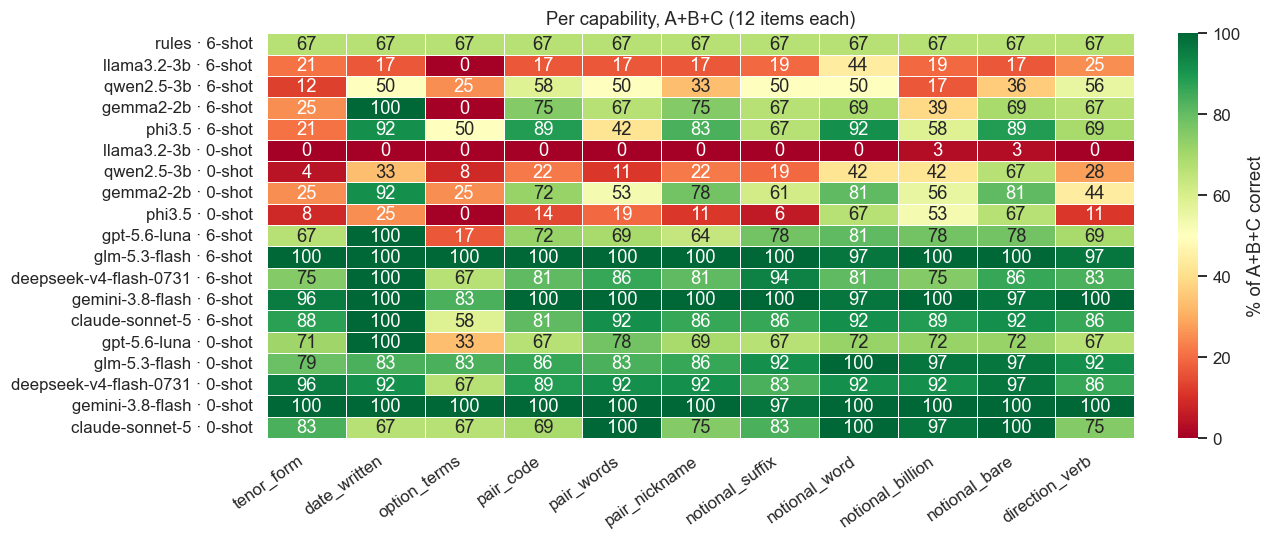

In [11]:
capability_pct = pd.DataFrame(index=headers["label"], columns=corpus.CAPABILITIES, dtype=float)
for rid in RUN_IDS:
    for capability, per_split in report.capability_summary(by_run[rid]).items():
        correct = sum(per_split[split]["correct"] for split in corpus.REPLICATES)
        n = sum(per_split[split]["n"] for split in corpus.REPLICATES)
        capability_pct.loc[LABEL[rid], capability] = 100 * report.rate(correct, n) if n else np.nan

fig, ax = plt.subplots(figsize=(11.5, 4.8))
sns.heatmap(
    capability_pct,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "% of A+B+C correct"},
    ax=ax,
)
ax.set_title("Per capability, A+B+C (12 items each)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
save(fig, "capability-heatmap")

The rule set scores the same everywhere: two familiar splits out of three, none of the
shifted one. It is the floor, not a competitor. The language models vary by tag, and
the hardest tag for them is `option_terms`. Section 12 covers how much of that is a
decline rather than a misread.

## 7. The refusal arm, in detail

Every D sentence carries the reason it is not a ticket, set on the item regardless of
what the model did, so it can be paired with the verdict. The reasons are different
checks, so one that no model passes points at that check rather than at the models.

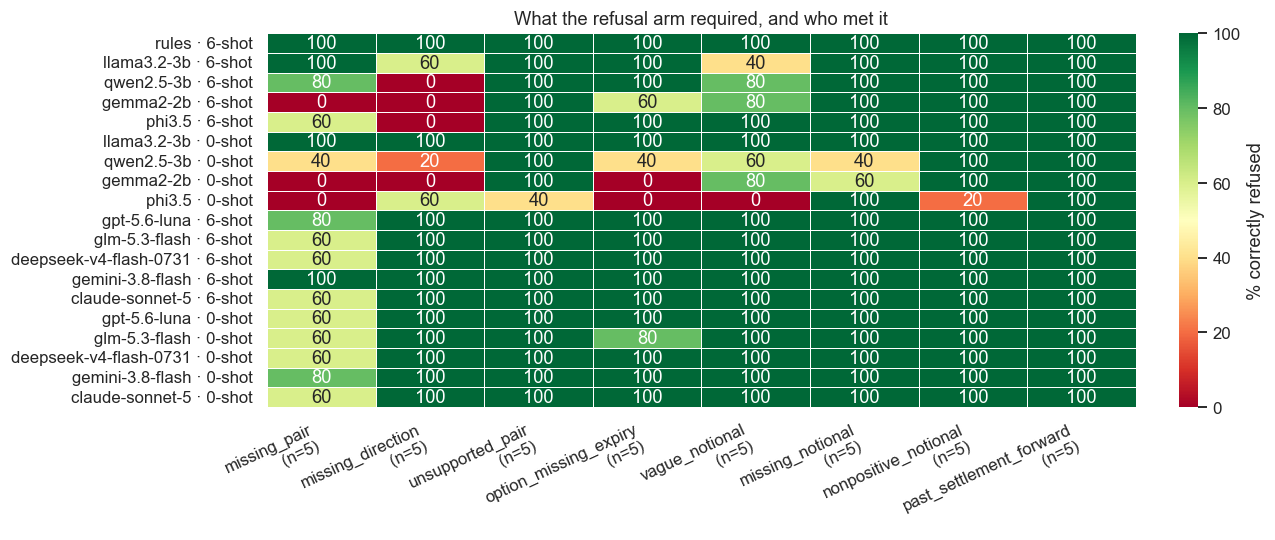

In [12]:
REASONS = list(report.reason_summary(by_run["baseline"]))
REASON_N = {reason: report.reason_summary(by_run["baseline"])[reason]["n"] for reason in REASONS}

reason_pct = pd.DataFrame(index=headers["label"], columns=REASONS, dtype=float)
for rid in RUN_IDS:
    per_reason = report.reason_summary(by_run[rid])
    for reason in REASONS:
        entry = per_reason.get(reason, {"n": 0, "correct": 0})
        reason_pct.loc[LABEL[rid], reason] = (
            100 * report.rate(entry["correct"], entry["n"]) if entry["n"] else np.nan
        )

fig, ax = plt.subplots(figsize=(11.5, 4.8))
sns.heatmap(
    reason_pct.set_axis([f"{r}\n(n={REASON_N[r]})" for r in REASONS], axis=1),
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "% correctly refused"},
    ax=ax,
)
ax.set_title("What the refusal arm required, and who met it")
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
save(fig, "refusal-reasons")

One column separates the models: `missing_direction`. Three of the four local models
score zero on it, so they will book a ticket that never says buy or sell, while every
hosted model meets it. The other checks are met by nearly everyone, since the prompt
defines a decline.

,refused,parsed,timeout,crashed,total
label,,,,,
rules · 6-shot,40,0,0,0,40
llama3.2-3b · 6-shot,35,5,0,0,40
qwen2.5-3b · 6-shot,33,7,0,0,40
gemma2-2b · 6-shot,27,13,0,0,40
phi3.5 · 6-shot,33,7,0,0,40
llama3.2-3b · 0-shot,40,0,0,0,40
qwen2.5-3b · 0-shot,25,15,0,0,40
gemma2-2b · 0-shot,22,18,0,0,40
phi3.5 · 0-shot,16,24,0,0,40


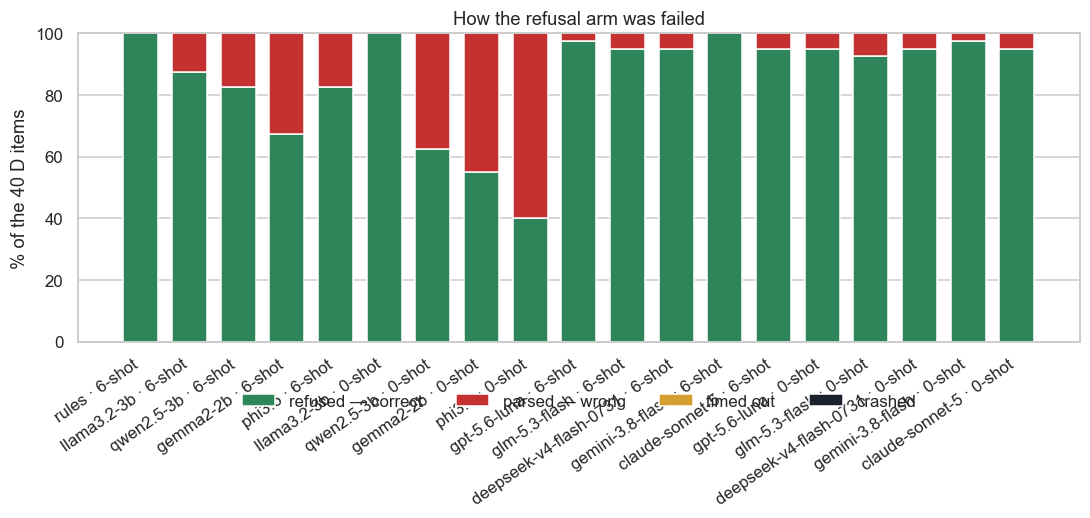

In [13]:
OUTCOME_ORDER = ["refused", "parsed", "timeout", "crashed"]
OUTCOME_COLOUR = {
    "refused": "#2f855a",
    "parsed": "#c53030",
    "timeout": "#d69e2e",
    "crashed": "#1a202c",
}
OUTCOME_TEXT = {
    "refused": "refused — correct",
    "parsed": "parsed — wrong",
    "timeout": "timed out",
    "crashed": "crashed",
}

refusal_stack = pd.DataFrame(
    [
        {
            "label": LABEL[rid],
            **{
                outcome: sum(
                    1
                    for r in by_run[rid]
                    if r["split"] == REFUSAL_ARM and r["outcome"] == outcome
                )
                for outcome in scoring.OUTCOMES
            },
        }
        for rid in RUN_IDS
    ]
).set_index("label")[OUTCOME_ORDER]
refusal_share = refusal_stack.div(refusal_stack.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9.8, 4.6))
bottom = np.zeros(len(refusal_share))
for outcome in OUTCOME_ORDER:
    ax.bar(
        refusal_share.index,
        refusal_share[outcome],
        bottom=bottom,
        width=0.72,
        color=OUTCOME_COLOUR[outcome],
        label=OUTCOME_TEXT[outcome],
    )
    bottom += refusal_share[outcome].to_numpy()
ax.set_ylabel("% of the 40 D items")
ax.set_title("How the refusal arm was failed")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
save(fig, "refusal-composition")

display(refusal_stack.assign(total=refusal_stack.sum(axis=1)))

## 8. What it cost

Price and latency belong to the deployment as much as to the model. Self-hosted runs
attract no API charge and take tens of seconds a sentence; hosted runs answer in a
few seconds and are billed. Counts sit beside every average, because a local model
reports no usage and an average over nothing is not a cheap run.

In [14]:
table_order = headers.assign(
    _family=headers["family"].map({"baseline": 0, "local": 1, "hosted": 2}),
    _condition=headers["condition"].map({"6-shot": 0, "0-shot": 1}),
).sort_values(["_family", "_condition", "label"])


def seconds(value_ms) -> str:
    # The baseline answers in process, in a fraction of a millisecond.
    if value_ms is None:
        return "—"
    return "<0.01" if value_ms < 5 else f"{value_ms / 1000:.2f}"


cost_rows = []
for rid in table_order["run_id"]:
    cost = report.cost_summary(by_run[rid])
    baseline = FAMILY[rid] == "baseline"
    hosted = FAMILY[rid] == "hosted"
    measured = cost["with_tokens"]
    cost_rows.append(
        {
            "run": "Rule-based" if baseline else LABEL[rid],
            "turns measured": "—" if baseline else f"{measured}/{cost['n']}",
            "tokens": f"{cost['total_tokens']:,}" if measured else "—",
            "tokens / turn": f"{cost['total_tokens'] / measured:,.0f}" if measured else "—",
            "cost (usd)": f"{cost['usd']:.4f}" if hosted else "—",
            "cost / turn (usd)": f"{cost['usd'] / cost['with_usd']:.5f}" if hosted else "—",
            "p50 latency (s)": seconds(cost["latency_p50_ms"]),
            "p95 latency (s)": seconds(cost["latency_p95_ms"]),
            "model time (s)": "<1" if baseline else f"{cost['latency_total_s']:,.0f}",
        }
    )
display(pd.DataFrame(cost_rows).set_index("run"))
print("turns measured is the count the tokens and the price were taken over, out of 376")
print(f"hosted spend, ten runs: ${sum(report.cost_summary(by_run[r])['usd'] or 0 for r in RUN_IDS):.4f}")

,turns measured,tokens,tokens / turn,cost (usd),cost / turn (usd),p50 latency (s),p95 latency (s),model time (s)
run,,,,,,,,
Rule-based,—,—,—,—,—,<0.01,<0.01,<1
gemma2-2b · 6-shot,336/376,"713,850","2,125",—,—,24.25,41.82,"9,712"
llama3.2-3b · 6-shot,149/376,"283,493","1,903",—,—,4.65,20.00,"3,839"
phi3.5 · 6-shot,310/376,"785,307","2,533",—,—,33.75,68.08,"13,442"
qwen2.5-3b · 6-shot,213/376,"439,594","2,064",—,—,16.34,22.93,"5,203"
gemma2-2b · 0-shot,322/376,"376,921","1,171",—,—,24.36,30.91,"9,386"
llama3.2-3b · 0-shot,3/376,"3,219","1,073",—,—,2.02,9.77,"1,407"
phi3.5 · 0-shot,337/376,"505,255","1,499",—,—,37.81,84.82,"15,634"
qwen2.5-3b · 0-shot,312/376,"372,856","1,195",—,—,19.71,38.98,"7,683"


turns measured is the count the tokens and the price were taken over, out of 376
hosted spend, ten runs: $8.6872


Table 4.6 is the frame above, with its columns named as the write-up names them.
Turns measured is the count the tokens and the price were taken over, and it is not
376 for any run that declines: usage is recorded on the path that returns a trade, so
a refusal, a timeout and a crash carry neither a token count nor a price. Tokens and
cost therefore describe the sentences a run answered, and the real spend behind a row
is higher, because a refusal still pays for its prompt. The effect is worst for
`llama3.2-3b` zero-shot, where three turns are measured: 1,073 tokens a turn is not a
cheap model, it is a model that declined 370 of 376 sentences.

Two things stand out in the table. Cost per turn separates the hosted models by a
factor of twenty-five, from `deepseek-v4-flash-0731` and `glm-5.3-flash` at under half
a thousandth of a dollar to `claude-sonnet-5` at nine thousandths. And six-shot costs
more per turn than zero-shot for every hosted model, since the worked examples are
resent with every call: `gpt-5.6-luna` goes from 1,077 tokens a turn to 1,901,
`claude-sonnet-5` from 1,962 to 2,917. Whatever the examples buy in accuracy, they are
not free.

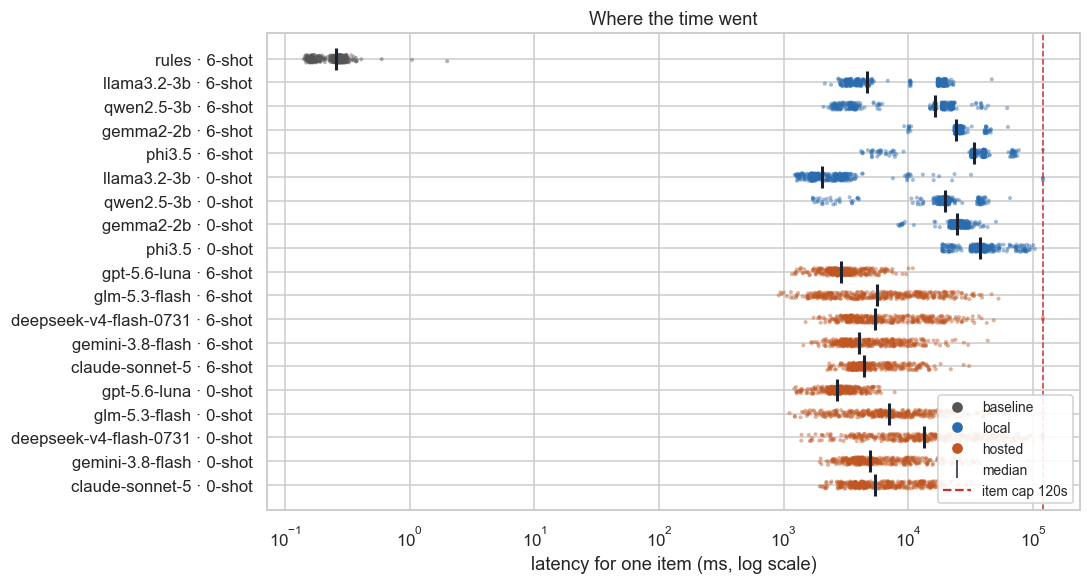

In [15]:
fig, ax = plt.subplots(figsize=(9.8, 5.2))
rng = np.random.default_rng(0)
cap_s = headers["item_timeout_s"].iloc[0]
for position, rid in enumerate(RUN_IDS):
    values = items.loc[items["run_id"] == rid, "latency_ms"].to_numpy()
    ax.scatter(
        values,
        position + rng.uniform(-0.16, 0.16, len(values)),
        s=7,
        alpha=0.45,
        color=FAMILY_COLOUR[FAMILY[rid]],
        edgecolor="none",
    )
    ax.plot(
        [report.percentile(sorted(values), 50)],
        [position],
        marker="|",
        markersize=15,
        markeredgewidth=2,
        color="#1a202c",
        zorder=4,
    )
ax.axvline(1000 * cap_s, color="#c53030", linestyle="--", linewidth=1)

family_handles = [
    Line2D([], [], marker="o", linestyle="none", color=colour, label=family)
    for family, colour in FAMILY_COLOUR.items()
]
ax.legend(
    handles=[
        *family_handles,
        Line2D([], [], color="#1a202c", marker="|", linestyle="none", markersize=12, label="median"),
        Line2D([], [], color="#c53030", linestyle="--", label=f"item cap {cap_s:g}s"),
    ],
    loc="lower right",
    frameon=True,
    framealpha=0.9,
    fontsize=9,
)
ax.set_xscale("log")
ax.set_yticks(range(len(RUN_IDS)))
ax.set_yticklabels([LABEL[rid] for rid in RUN_IDS])
ax.invert_yaxis()
ax.set_xlabel("latency for one item (ms, log scale)")
ax.set_title("Where the time went")
save(fig, "latency")

The pile-up on the right-hand line is the harness cutting a model off. A model that
never stops is recorded as a timeout, not as a slow answer. Only two models have any:
a sentence a model declines comes back as one short object instead of a whole trade.

## 9. Failure forensics

`crashed` means the harness faulted, not that the model answered badly. A dead
provider, a missing frozen rate, a null reply. The exception type stays on the record
so a system fault can be told from a model fault.

In [16]:
fault_rows = [
    {
        "label": LABEL[rid],
        "outcome": outcome,
        "error": error_type,
        "items": count,
    }
    for rid in RUN_IDS
    for outcome, errors in report.error_summary(by_run[rid]).items()
    if outcome in (scoring.CRASHED, scoring.TIMEOUT)
    for error_type, count in errors.items()
]
display(pd.DataFrame(fault_rows).sort_values("items", ascending=False))
print("crashes and timeouts only — a refusal carries an error message too, and is not a fault")

,label,outcome,error,items
5,deepseek-v4-flash-0731 · 0-shot,timeout,TimeoutError,6
3,gemini-3.8-flash · 6-shot,crashed,RuntimeError,4
1,llama3.2-3b · 0-shot,timeout,TimeoutError,3
2,deepseek-v4-flash-0731 · 6-shot,timeout,TimeoutError,2
0,phi3.5 · 6-shot,timeout,TimeoutError,1
4,glm-5.3-flash · 0-shot,timeout,TimeoutError,1
6,gemini-3.8-flash · 0-shot,crashed,RuntimeError,1


crashes and timeouts only — a refusal carries an error message too, and is not a fault


In [17]:
misread_rows = []
for rid in RUN_IDS:
    misreads = report.field_tally(by_run[rid])
    misread_rows.append(
        {
            "label": LABEL[rid],
            "misread fields": sum(misreads.values()),
            "most often wrong": ", ".join(
                f"{name} ({count})" for name, count in misreads.most_common(4)
            )
            or "—",
        }
    )
display(pd.DataFrame(misread_rows))

,label,misread fields,most often wrong
0,rules · 6-shot,40,"instrument_type: 'SPOT' != 'FORWARD' (5), instrument.instrument_type: 'SPOT' != 'FORWARD' (5), instrument.settlement_date: '2026-09-15' != '2026-11-10' (2), instrument.settlement_date: '2026-09-15' != '2026-10-26' (2)"
1,llama3.2-3b · 6-shot,85,"instrument.delivery_date: None != '2026-10-21' (27), instrument.delivery_date: None != '2027-03-22' (18), instrument.delivery_date: None != '2026-12-22' (8), notional_1: 80000000.0 != 8000000.0 (7)"
2,qwen2.5-3b · 6-shot,85,"instrument.delivery_date: '2026-12-20' != '2026-12-22' (15), instrument.delivery_date: None != '2026-12-22' (10), notional_1: 600000.0 != 6000000.0 (10), notional_1: 900000.0 != 9000000.0 (6)"
3,gemma2-2b · 6-shot,133,"instrument.delivery_date: None != '2026-10-21' (51), instrument.delivery_date: None != '2027-03-22' (28), instrument.delivery_date: None != '2026-12-22' (12), instrument.settlement_date: '2026-10-27' != '2026-09-29' (3)"
4,phi3.5 · 6-shot,92,"instrument.delivery_date: '2027-03-20' != '2027-03-22' (29), direction: 'SELL' != 'BUY' (29), instrument.settlement_date: '2026-09-18' != '2026-09-29' (2), instrument.settlement_date: '2026-12-15' != '2027-03-15' (2)"
5,llama3.2-3b · 0-shot,2,"notional_1: 9.0 != 9000000.0 (1), instrument.delivery_date: '2027-03-20' != '2027-03-22' (1)"
6,qwen2.5-3b · 0-shot,282,"instrument.delivery_date: None != '2026-10-21' (37), instrument.delivery_date: None != '2027-03-22' (28), direction: 'SELL' != 'BUY' (26), instrument.delivery_date: None != '2026-12-22' (23)"
7,gemma2-2b · 0-shot,129,"direction: 'SELL' != 'BUY' (20), instrument.delivery_date: '2026-12-20' != '2026-12-22' (19), instrument.delivery_date: None != '2027-03-22' (14), instrument.delivery_date: '2027-03-20' != '2027-03-22' (11)"
8,phi3.5 · 0-shot,307,"instrument.delivery_date: '2026-11-01' != '2026-10-21' (43), direction: 'SELL' != 'BUY' (23), instrument.delivery_date: '2026-12-20' != '2026-12-22' (21), notional_1: 1.0 != 1000000.0 (18)"
9,gpt-5.6-luna · 6-shot,0,—


A decline names no misread field, so the field tally reads clean for the runs that
lost the most items. Read it next to the refusal count, not on its own.

## 10. What the score rests on, and whether the ledger holds together

The resolver fills any field a draft leaves unspecified, and those fills are
recorded. A run that scores well while defaulting much of the draft has measured the
defaults too, so the table belongs next to the accuracy.

In [18]:
default_rows = []
for rid in RUN_IDS:
    defaults = report.default_summary(by_run[rid])
    default_rows.append(
        {
            "label": LABEL[rid],
            "items with defaults": f"{defaults['items_with_defaults']}/{defaults['n']}",
            "defaults": defaults["default_count"],
            "most defaulted": ", ".join(
                f"{name} ({count})" for name, count in defaults["fields"].most_common(3)
            )
            or "—",
        }
    )
display(pd.DataFrame(default_rows))

,label,items with defaults,defaults,most defaulted
0,rules · 6-shot,100/376,204,"premium_date (100), exercise_style (100), premium (2)"
1,llama3.2-3b · 6-shot,65/376,135,"premium_date (60), delivery_date (53), exercise_style (22)"
2,qwen2.5-3b · 6-shot,109/376,126,"premium_date (104), delivery_date (17), settlement_date (5)"
3,gemma2-2b · 6-shot,115/376,216,"premium_date (114), delivery_date (96), exercise_style (5)"
4,phi3.5 · 6-shot,115/376,115,"premium_date (114), settlement_date (1)"
5,llama3.2-3b · 0-shot,0/376,0,—
6,qwen2.5-3b · 0-shot,110/376,242,"premium_date (100), delivery_date (88), exercise_style (44)"
7,gemma2-2b · 0-shot,19/376,38,"premium_date (19), delivery_date (19)"
8,phi3.5 · 0-shot,4/376,4,"exercise_style (3), premium (1)"
9,gpt-5.6-luna · 6-shot,32/376,47,"premium_date (32), exercise_style (15)"


In [19]:
faults = [
    (rid, problem)
    for rid in RUN_IDS
    for problem in report.integrity_problems(by_run[rid])
]
print(f"integrity: {len(faults)} self-contradicting records across {len(items)} item records")
for rid, problem in faults:
    print(" ", rid, "—", problem)

reference = headers.iloc[0].to_dict()
incomparable = {
    LABEL[row["run_id"]]: report.compare_headers(reference, row)
    for row in headers.to_dict("records")
    if report.compare_headers(reference, row)
}
print()
print(f"comparable to {LABEL[reference['run_id']]} on {report.COMPARABLE_FIELDS}:")
print(" ", incomparable or f"all {len(headers)} agree")

integrity: 0 self-contradicting records across 7144 item records

comparable to rules · 6-shot on ('corpus_sha256', 'system_prompt_sha256', 'runner_version', 'scorer_version', 'splits'):
  all 19 agree


`integrity_problems` checks the ledger, not the models. A record that contradicts
itself, marked correct while naming a wrong field, cannot come out of a correct run,
so a line here would be a fault in the evidence. There are none.

The second check is comparability. Two runs may only be differenced when they asked
the same questions under the same rules, which is what `compare_headers` asserts.

## 11. Per-run profiles

Nine quantities per run on one set of axes. Three views of the same numbers: each
model with its two conditions side by side, then every 6-shot run together, then every
0-shot run together. Within a single-condition chart the colour identifies the run; in
the paired view the colour identifies the condition and each model has its own radar.

Each rate is taken over the pool it can apply to. `refused D` is out of the 40
sentences that should be refused; `parsed ABC`, `refused ABC` and `correct ABC` are out
of the 336 that should book; the faults are out of all 376 items. Those six are drawn
as they are, so a radius of 0.5 means 50%. The three cost axes are in unrelated units,
so each is scaled from the worst run to the best and reads as a ranking, not a value.

Two axes point opposite ways. `refused D` counts the refusals that should happen, so
larger is better; `refused ABC` counts the refusals that should not, so larger is
worse. `crashed` and `timeout` are faults in the run rather than answers from the
model.

In [20]:
#: The spoke order, clockwise from the top. Every rate names the pool it is taken over:
#: a refusal on D is out of the 40 sentences that should be refused, and what the parse
#: arm does is out of the 336 that should book. Faults are out of all 376 items.
PROFILE_AXES = [
    "refused D /40",
    "parsed ABC /336",
    "refused ABC /336",
    "correct ABC /336",
    "crashed /376",
    "timeout /376",
    "tokens (scaled)",
    "usd (scaled)",
    "latency (scaled)",
]
RATE_AXES = PROFILE_AXES[:6]
SCALED_AXES = PROFILE_AXES[6:]


def profile(rid: str) -> dict:
    rows = by_run[rid]
    booking = [r for r in rows if r["split"] in PARSE_ARM]
    refused_pool = [r for r in rows if r["split"] == REFUSAL_ARM]

    def share(predicate, pool) -> float:
        return sum(1 for r in pool if predicate(r)) / len(pool) if pool else 0.0

    tokens = [r["total_tokens"] for r in rows if r["total_tokens"] is not None]
    usd = [r["usd"] for r in rows if r["usd"] is not None]
    return {
        "refused D /40": share(lambda r: r["outcome"] == scoring.REFUSED, refused_pool),
        "parsed ABC /336": share(lambda r: r["outcome"] == scoring.PARSED, booking),
        "refused ABC /336": share(lambda r: r["outcome"] == scoring.REFUSED, booking),
        "correct ABC /336": share(lambda r: r["correct"], booking),
        "crashed /376": share(lambda r: r["outcome"] == scoring.CRASHED, rows),
        "timeout /376": share(lambda r: r["outcome"] == scoring.TIMEOUT, rows),
        # Local runs report tokens but no price, so ``usd`` is 0 for them by absence
        # rather than by being free. For a hosted run the mean is over the items that
        # carried a cost, since a declined item's usage is dropped.
        "tokens (scaled)": sum(tokens) / len(tokens) if tokens else 0.0,
        "usd (scaled)": sum(usd) / len(usd) if usd else 0.0,
        "latency (scaled)": sum(r["latency_ms"] for r in rows) / len(rows),
    }


raw_profile = pd.DataFrame({rid: profile(rid) for rid in RUN_IDS}).T
# The rates are already a fraction of their own pool, so they keep their scale. The
# three cost axes are on unrelated units; min-max across the runs puts the best at 1.
costs = raw_profile[SCALED_AXES]
profile_pct = raw_profile[PROFILE_AXES].copy()
profile_pct[SCALED_AXES] = (costs - costs.min()) / (costs.max() - costs.min()).replace(0.0, 1.0)

display(
    pd.DataFrame(
        {
            "run": [LABEL[rid] for rid in RUN_IDS],
            **{
                axis: [f"{100 * raw_profile.loc[rid, axis]:.1f}%" for rid in RUN_IDS]
                for axis in RATE_AXES
            },
            "tokens": [f"{raw_profile.loc[rid, 'tokens (scaled)']:,.0f}" for rid in RUN_IDS],
            "usd": [f"${raw_profile.loc[rid, 'usd (scaled)']:.4f}" for rid in RUN_IDS],
            "latency": [f"{raw_profile.loc[rid, 'latency (scaled)']:,.0f}ms" for rid in RUN_IDS],
        }
    ).set_index("run")
)

,refused D /40,parsed ABC /336,refused ABC /336,correct ABC /336,crashed /376,timeout /376,tokens,usd,latency
run,,,,,,,,,
rules · 6-shot,100.0%,75.0%,25.0%,66.7%,0.0%,0.0%,0,$0.0000,0ms
llama3.2-3b · 6-shot,87.5%,42.9%,57.1%,20.8%,0.0%,0.0%,"1,903",$0.0000,"10,211ms"
qwen2.5-3b · 6-shot,82.5%,61.3%,38.7%,41.1%,0.0%,0.0%,"2,064",$0.0000,"13,839ms"
gemma2-2b · 6-shot,67.5%,96.1%,3.9%,61.9%,0.0%,0.0%,"2,125",$0.0000,"25,830ms"
phi3.5 · 6-shot,82.5%,90.2%,9.5%,69.6%,0.0%,0.3%,"2,533",$0.0000,"35,749ms"
llama3.2-3b · 0-shot,100.0%,0.9%,98.2%,0.6%,0.0%,0.8%,"1,073",$0.0000,"3,741ms"
qwen2.5-3b · 0-shot,62.5%,88.4%,11.6%,28.9%,0.0%,0.0%,"1,195",$0.0000,"20,433ms"
gemma2-2b · 0-shot,55.0%,90.5%,9.5%,62.2%,0.0%,0.0%,"1,171",$0.0000,"24,963ms"
phi3.5 · 0-shot,40.0%,93.2%,6.8%,28.0%,0.0%,0.0%,"1,499",$0.0000,"41,580ms"


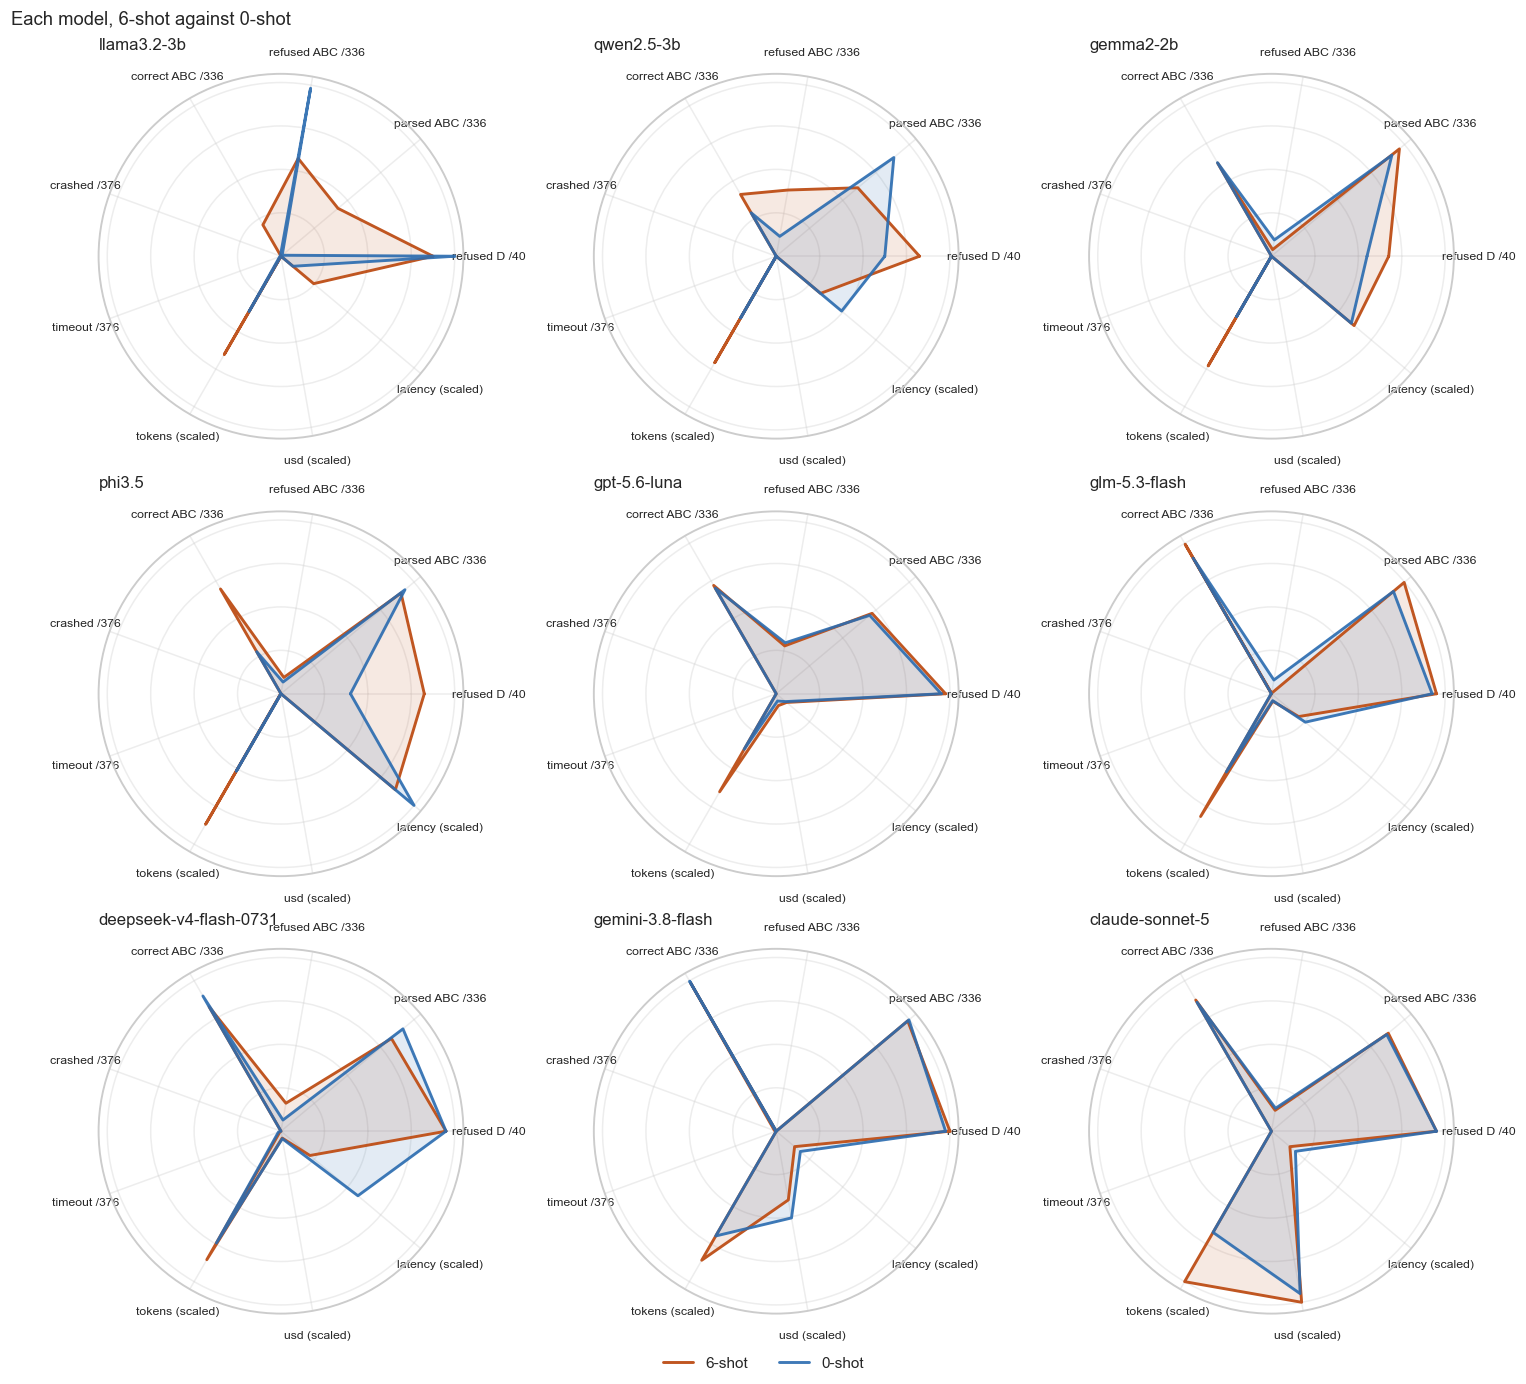

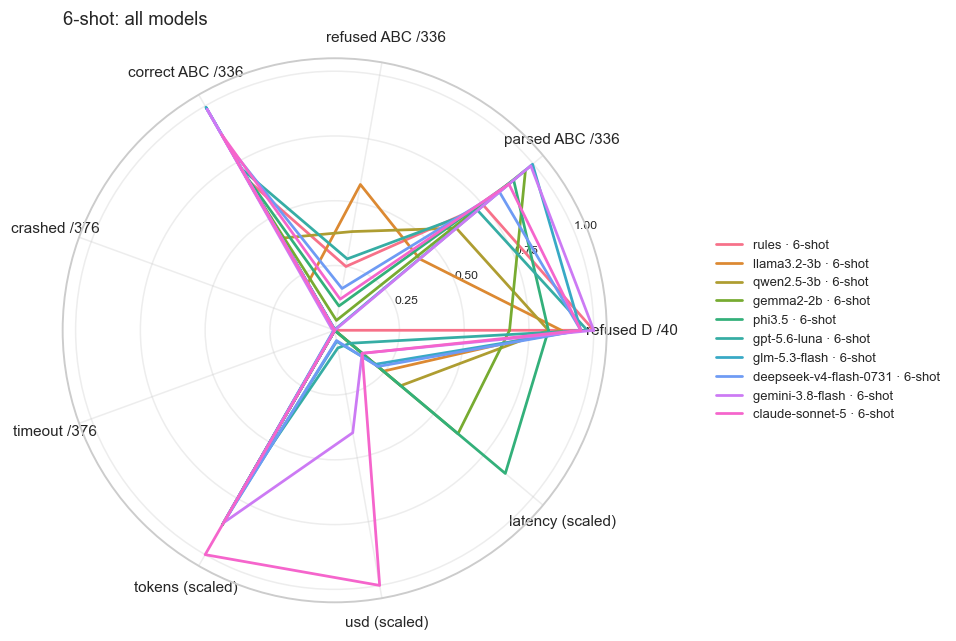

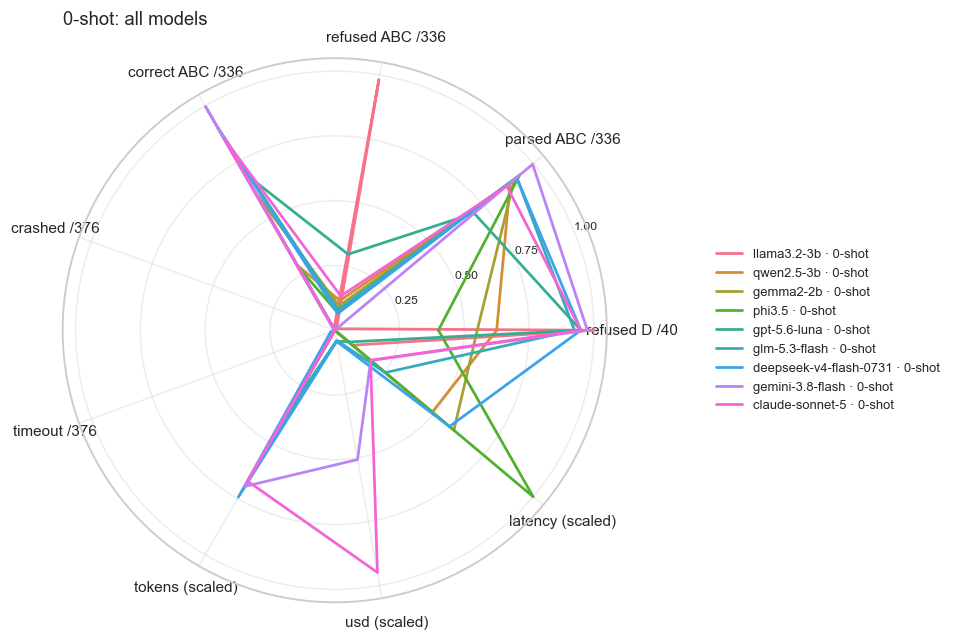

In [21]:
angles = np.linspace(0, 2 * np.pi, len(PROFILE_AXES), endpoint=False)
closed = np.concatenate([angles, angles[:1]])
SIX_SHOT = list(headers.loc[headers["condition"] == "6-shot", "run_id"])
ZERO_SHOT = list(headers.loc[headers["condition"] == "0-shot", "run_id"])


def left_title(ax, text: str, *, size=11, pad=14, x=-0.16) -> None:
    # Hung off the left of the axes box rather than centred over the circle. The polar
    # circle is inscribed in a square, so a negative x clears the empty corner.
    ax.set_title(text, fontsize=size, pad=pad, loc="left")
    ax.title.set_x(x)


def radar(ax, run_ids, title, *, outside_legend=False, label_size=10) -> None:
    # One radar over ``run_ids``, a colour each, on the shared min-max scale.
    palette = sns.color_palette("husl", len(run_ids))
    for rid, colour in zip(run_ids, palette):
        values = profile_pct.loc[rid].to_numpy()
        ax.plot(
            closed,
            np.concatenate([values, values[:1]]),
            color=colour,
            linewidth=1.8,
            label=LABEL[rid],
            zorder=3,
        )
    ax.set_xticks(angles)
    ax.set_xticklabels(PROFILE_AXES, fontsize=label_size)
    ax.set_ylim(0, 1.05)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=8)
    ax.grid(alpha=0.35)
    left_title(ax, title, size=12, pad=22, x=-0.46)
    if outside_legend:
        ax.legend(
            bbox_to_anchor=(1.18, 0.5), loc="center left", fontsize=8.5, frameon=False
        )


# One model per radar, so the two conditions can be read against each other directly.
MODELS = [m for m in dict.fromkeys(headers["model_id"]) if m != "rule-based"]
CONDITION_STYLE = {"6-shot": ("#c05621", 1.0), "0-shot": ("#2b6cb0", 0.9)}

fig, grid = plt.subplots(
    3, 3, figsize=(13.5, 12.5), subplot_kw={"projection": "polar"}, constrained_layout=True
)
fig.suptitle("Each model, 6-shot against 0-shot", fontsize=12, x=-0.02, ha="left")
for ax, model in zip(grid.ravel(), MODELS):
    for condition, (colour, alpha) in CONDITION_STYLE.items():
        match = arm[(arm["model_id"] == model) & (arm["condition"] == condition)]
        if match.empty:
            continue
        values = profile_pct.loc[match["run_id"].iloc[0]].to_numpy()
        values = np.concatenate([values, values[:1]])
        ax.plot(closed, values, color=colour, linewidth=1.9, alpha=alpha, zorder=3)
        ax.fill(closed, values, color=colour, alpha=0.13, zorder=2)
    ax.set_xticks(angles)
    ax.set_xticklabels(PROFILE_AXES, fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels([])
    ax.grid(alpha=0.35)
    left_title(ax, short_label(model), size=11, pad=16, x=-0.34)
fig.legend(
    handles=[
        Line2D([], [], color=colour, linewidth=1.9, alpha=alpha, label=condition)
        for condition, (colour, alpha) in CONDITION_STYLE.items()
    ],
    loc="outside lower center",
    ncols=2,
    fontsize=10,
    frameon=False,
)
save(fig, "profiles-paired")

# Then one chart per condition, where every line is a different model. Nine or ten
# lines is few enough to follow individually, which nineteen was not.
for run_ids, condition, filename in (
    (SIX_SHOT, "6-shot", "profiles-6shot"),
    (ZERO_SHOT, "0-shot", "profiles-0shot"),
):
    fig, ax = plt.subplots(figsize=(8.6, 8.2), subplot_kw={"projection": "polar"})
    radar(ax, run_ids, f"{condition}: all models", outside_legend=True)
    save(fig, filename)
    plt.show()

Read a chart as a shape, not as an area, and take numbers from the table above rather
than from a line. The paired view is the one to use for a single model; the two
single-condition charts are for comparing models within a condition.

On the six rate axes the radius is the rate itself, so the rings are percentages. On
`tokens`, `usd` and `latency` the radius is only a position between the best and worst
run, so those three spokes compare runs but do not read as a value.

A model that declines almost everything has a spike on `refused D` and a matching
spike on `refused ABC`. Those two together mean something different from either on its
own. The `usd` axis is 0 for every local model, which is absence of a price rather
than a price of zero.

## 12. What to read with care

The demonstration count is recorded on the later runs only. `shots` and
`instruction_sha256` went into the header after the first ten runs were written, so
those ten carry neither, and their condition is known from the run order rather than
from the record.

A decline is scored like a wrong answer, and declines are now the commoner failure.
The hardest tag for the language models is `option_terms`, and much of that is a
decline rather than a misread: several models refuse an option ticket for not stating
`exercise_style`, a field the corpus treats as a resolver default and never scores.
Over-declining costs one model nearly every valid item and another none at all, so
read a capability row next to that model's refusal count.

A fix to a golden is a re-score, not a re-run. The ledger stores the model's own JSON
under `raw`, and `scoring.verdict` is a pure function of that draft and the golden, so
a corrected golden can be applied to answers already recorded without calling a model
again. Seconds, and no spend. The header's `corpus_sha256` records which golden set a
verdict came from, and a rescored run would carry a different one.

A crash is not a wrong answer. Check `error_type` before reading a miss as a parse
failure. Five records are crashes rather than answers, all of them gemini-3.8-flash:
four in the six-shot run and one in the zero-shot run, each a reply that arrived with
no message content at all. The four are four of the six-shot run's five parse-arm
misses, so setting provider faults aside moves that arm from 98.5% to 99.7%, and every
other arm item in the zero-shot run is correct.

Declines are not priced. A refusal propagates as an exception, so the usage the
provider reported is dropped on the way out. The `turns measured` column in Table 4.6
is the count the tokens and the price were taken over, and the hosted runs are missing
a large share of theirs. The dollar totals are a floor, not the spend, and the missing
share scales with how often a model declines.

Cost is not stable per item. In the zero-shot `glm-5.3-flash` run, items A-064 and
C-041 each returned 1,106 tokens, and the response named `z-ai/glm-5.3-flash` both
times, yet one was billed $0.000037 and the other $0.000234, a factor of 6.35. Of the
2,738 request sizes the hosted runs measured, only eleven carry more than one price,
and nine of those eleven are this model; the other two are `deepseek-v4-flash-0731`.
`gpt-5.6-luna`, `gemini-3.8-flash` and `claude-sonnet-5` never quote two prices for a
single request size. Treat the totals as an order of magnitude, not a rate card.

The numbers above are as measured. Nothing is corrected, adjusted or excluded. Every
rate is printed with the denominator it was taken over.

The profile charts mix two scales. The six rate axes are absolute, taken over the pool
named in the label; the three cost axes are each scaled from the worst run to the best,
so only their order carries meaning.